# PPO from Pixels: ViZDoom, Asynchronous PPO and RLlib APPO

*PPO and curiosity → **PPO from pixels***

The [Hugging Face Deep RL Course, Unit 8 Part 2](https://huggingface.co/learn/deep-rl-course/unit8/introduction-sf)
trains an agent to play the ViZDoom level **Health Gathering Supreme** from raw pixels, using **Sample Factory**:
a highly optimized, *asynchronous* PPO (APPO) that you drive through command-line flags.

Here we keep the task and update the tools:

| Part | What | Replaces in the course |
|---|---|---|
| A | **ViZDoom with Gymnasium**: scenarios, pixel preprocessing, frame stacking | Sample Factory's Doom wrappers |
| B | **Our PPO goes visual**: a CNN, `AsyncVectorEnv`, and the Apple GPU (MPS) or CUDA | |
| C | **Synchronous vs asynchronous PPO**: policy lag and **V-trace**, implemented and checked | what the "A" in APPO means |
| D | **RLlib APPO** on Health Gathering Supreme: parallel env runners, video, Hub upload | `sample-factory` training |
| E | Appendix: the original Sample Factory commands, mapped to RLlib | |

**Hardware.** Training from pixels is heavy:
- **Locally** (CPU or Apple GPU), use the small scenarios, `Basic` and `DefendCenter`. They learn in minutes to an hour.
- For **Health Gathering Supreme**, which needs several million steps, use a CUDA GPU (Colab or Linux) if you can.
- Every long run is behind a flag, so the notebook runs end to end quickly.

In [1]:
# !pip install vizdoom gymnasium torch opencv-python matplotlib imageio imageio-ffmpeg "ray[rllib]" huggingface_hub
import os
import platform
import random
import sys
import time
from dataclasses import dataclass, replace
from pathlib import Path

import cv2
import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.distributions import Categorical

import vizdoom
from vizdoom import gymnasium_wrapper  # noqa: F401   (registers the Vizdoom* Gymnasium environments)

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")          # Apple Silicon GPU
else:
    DEVICE = torch.device("cpu")

print("python", sys.version.split()[0], "| gymnasium", gym.__version__, "| torch", torch.__version__,
      "| vizdoom", vizdoom.__version__, "| device:", DEVICE, "|", platform.system(), platform.machine())
assert hasattr(gym.vector, "AutoresetMode"), "this notebook needs gymnasium >= 1.1 (pip install -U gymnasium)"


def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)


def smooth(x, k=20):
    x = np.asarray(x, dtype=float)
    return np.convolve(x, np.ones(k) / k, mode="valid") if len(x) >= k else x

python 3.11.17 | gymnasium 1.2.2 | torch 2.14.1 | vizdoom 1.3.2 | device: mps | Darwin arm64


# Part A: ViZDoom with Gymnasium

ViZDoom (Farama Foundation) is a lightweight Doom engine for RL research. It renders thousands of frames per second on
one CPU core and runs on Linux, macOS and Windows. Its scenarios are registered as Gymnasium environments. Names and
versions change between releases, so we look them up instead of hard-coding them.

In [2]:
def vizdoom_ids():
    from vizdoom import gymnasium_wrapper  # noqa: F401  (also needed inside worker processes)
    return sorted(e for e in gym.envs.registry if e.startswith("Vizdoom") and "MultiBinary" not in e)


def vizdoom_id(scenario):
    '''"HealthGatheringSupreme" -> e.g. "VizdoomHealthGatheringSupreme-v0" (newest registered version).'''
    matches = [e for e in vizdoom_ids() if e.split("-")[0] == f"Vizdoom{scenario}"]
    if not matches:
        raise ValueError(f"no ViZDoom env for scenario {scenario!r}; available: {vizdoom_ids()}")
    return matches[-1]


print("available scenarios:", [e.split("-")[0].replace("Vizdoom", "") for e in vizdoom_ids()])

for scenario in ["Basic", "DefendCenter", "HealthGatheringSupreme"]:
    e = gym.make(vizdoom_id(scenario))
    print(f"\n{vizdoom_id(scenario)}\n  observation: {e.observation_space}\n  actions:     {e.action_space}")
    e.close()

available scenarios: ['Basic', 'BasicAudio', 'BasicNotifications', 'DeadlyCorridor', 'Deathmatch', 'DefendCenter', 'DefendLine', 'Doom2MAP01', 'Doom2MAP01', 'Doom2MAP01', 'Doom2MAP01', 'Doom2MAP01', 'Doom2MAP02', 'Doom2MAP02', 'Doom2MAP02', 'Doom2MAP02', 'Doom2MAP02', 'Doom2MAP03', 'Doom2MAP03', 'Doom2MAP03', 'Doom2MAP03', 'Doom2MAP03', 'Doom2MAP04', 'Doom2MAP04', 'Doom2MAP04', 'Doom2MAP04', 'Doom2MAP04', 'Doom2MAP05', 'Doom2MAP05', 'Doom2MAP05', 'Doom2MAP05', 'Doom2MAP05', 'Doom2MAP06', 'Doom2MAP06', 'Doom2MAP06', 'Doom2MAP06', 'Doom2MAP06', 'Doom2MAP07', 'Doom2MAP07', 'Doom2MAP07', 'Doom2MAP07', 'Doom2MAP07', 'Doom2MAP08', 'Doom2MAP08', 'Doom2MAP08', 'Doom2MAP08', 'Doom2MAP08', 'Doom2MAP09', 'Doom2MAP09', 'Doom2MAP09', 'Doom2MAP09', 'Doom2MAP09', 'Doom2MAP10', 'Doom2MAP10', 'Doom2MAP10', 'Doom2MAP10', 'Doom2MAP10', 'Doom2MAP11', 'Doom2MAP11', 'Doom2MAP11', 'Doom2MAP11', 'Doom2MAP11', 'Doom2MAP12', 'Doom2MAP12', 'Doom2MAP12', 'Doom2MAP12', 'Doom2MAP12', 'Doom2MAP13', 'Doom2MAP13', 'Do

objc[21078]: Class SDL_RumbleMotor is implemented in both /Users/harvindersingh/miniforge3/envs/rl/lib/python3.11/site-packages/cv2/.dylibs/libSDL2-2.0.0.dylib (0x10e28cd40) and /Users/harvindersingh/miniforge3/envs/rl/lib/python3.11/site-packages/pygame/.dylibs/libSDL2-2.0.0.dylib (0x1166a49c8). This may cause spurious casting failures and mysterious crashes. One of the duplicates must be removed or renamed.
objc[21078]: Class SDL_RumbleContext is implemented in both /Users/harvindersingh/miniforge3/envs/rl/lib/python3.11/site-packages/cv2/.dylibs/libSDL2-2.0.0.dylib (0x10e28cd90) and /Users/harvindersingh/miniforge3/envs/rl/lib/python3.11/site-packages/pygame/.dylibs/libSDL2-2.0.0.dylib (0x1166a4a18). This may cause spurious casting failures and mysterious crashes. One of the duplicates must be removed or renamed.
objc[21078]: Class SDLApplication is implemented in both /Users/harvindersingh/miniforge3/envs/rl/lib/python3.11/site-packages/cv2/.dylibs/libSDL2-2.0.0.dylib (0x10e28c890)

| Scenario | Goal | Reward (roughly) | Difficulty |
|---|---|---|---|
| **Basic** | shoot the single monster in front of you | +100 for the kill, −1 per step, −5 per missed shot | minutes |
| **DefendCenter** | stand in the middle and shoot the monsters closing in | +1 per kill, −1 for dying | ~1M steps |
| **HealthGatheringSupreme** | collect health packs on an acid floor and avoid poison vials | a small reward for staying alive, a penalty for dying | several M steps |

Our rewards are ViZDoom's built-in ones. The course's Sample Factory setup adds its own reward shaping, so its
"mean reward" numbers are **not directly comparable** to ours.

### Pixel preprocessing

The same idea as Atari in notebook 3:
1. Keep only the `screen` image.
2. Convert to grayscale and resize to 84×84.
3. Repeat each action for `frame_skip = 4` game tics. ViZDoom does this natively, and quickly.
4. Stack the last 4 frames, so the network can see motion.

processed observation: (4, 84, 84) uint8 | actions: Discrete(4)


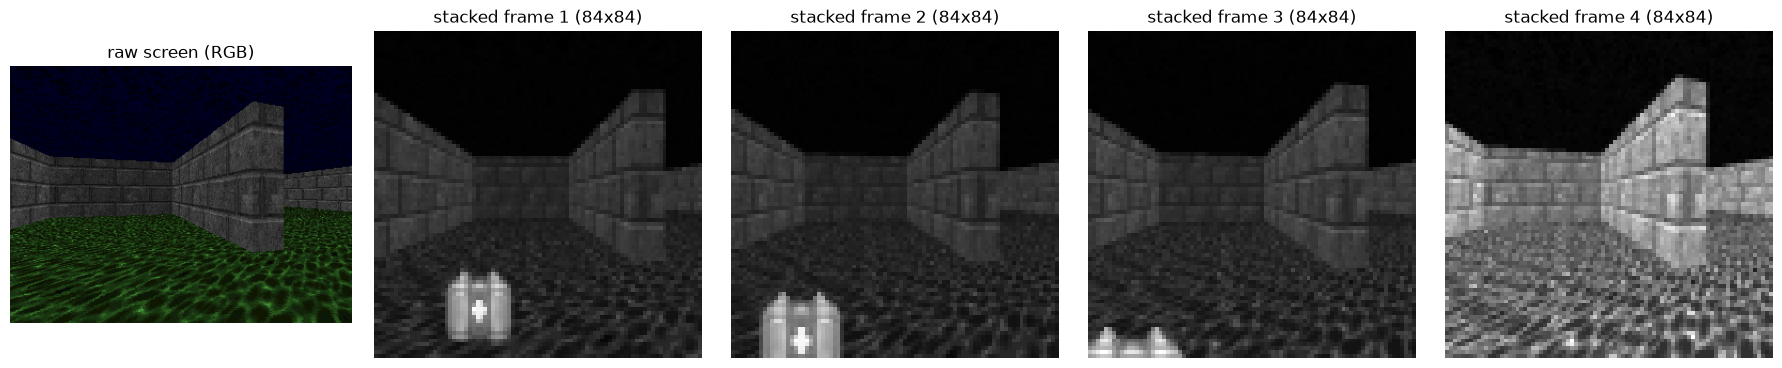

In [3]:
class DoomPixels(gym.ObservationWrapper):
    '''ViZDoom dict observation -> grayscale (size x size) uint8 image. Keeps the last RGB screen for videos.'''
    def __init__(self, env, size=84):
        super().__init__(env)
        self.size = size
        self.observation_space = gym.spaces.Box(0, 255, shape=(size, size), dtype=np.uint8)
        self.last_rgb = None

    def observation(self, obs):
        screen = obs["screen"] if isinstance(obs, dict) else obs
        if screen.ndim == 3 and screen.shape[-1] == 1:          # already grayscale (GRAY8 screen format)
            gray, self.last_rgb = screen[..., 0], np.repeat(screen, 3, axis=-1)
        else:
            gray, self.last_rgb = cv2.cvtColor(screen, cv2.COLOR_RGB2GRAY), screen
        return cv2.resize(gray, (self.size, self.size), interpolation=cv2.INTER_AREA)


def make_doom_env(scenario="Basic", frame_skip=4, size=84, frame_stack=4):
    env = gym.make(vizdoom_id(scenario), frame_skip=frame_skip)
    env = DoomPixels(env, size=size)
    return gym.wrappers.FrameStackObservation(env, frame_stack)        # -> (frame_stack, size, size) uint8


env = make_doom_env("HealthGatheringSupreme")
obs, _ = env.reset(seed=0)
for _ in range(8):
    obs, *_ = env.step(env.action_space.sample())
print("processed observation:", obs.shape, obs.dtype, "| actions:", env.action_space)

fig, ax = plt.subplots(1, 5, figsize=(18, 3.6))
ax[0].imshow(env.env.last_rgb)          # env.env = our DoomPixels wrapper (inside FrameStackObservation)
ax[0].set_title("raw screen (RGB)")
for i in range(4):
    ax[i + 1].imshow(obs[i], cmap="gray"); ax[i + 1].set_title(f"stacked frame {i + 1} (84x84)")
for a in ax:
    a.axis("off")
plt.tight_layout(); plt.show()
env.close()

### Many environments in parallel: `AsyncVectorEnv`

With pixels, both rendering and the network are expensive, so we run `n_envs` copies of the game in **separate
processes** with Gymnasium's `AsyncVectorEnv`.

One detail matters for correctness: what happens when one of the environments finishes an episode. We use
`AutoresetMode.SAME_STEP`, which needs Gymnasium ≥ 1.1:
- The finished environment is reset **in the same `step()` call**, so the returned observation is already the
  first frame of the new episode.
- The true final observation is in `info["final_obs"]`. We need it to bootstrap after a time-limit truncation,
  just as in notebooks 5 and 6.

`vector_mode="sync"` runs everything in one process instead. That's slower, but handy for debugging.

In [4]:
def make_vector_env(scenario, n_envs, frame_skip=4, size=84, frame_stack=4, mode="async"):
    fns = [lambda: make_doom_env(scenario, frame_skip, size, frame_stack) for _ in range(n_envs)]
    VecEnv = gym.vector.AsyncVectorEnv if mode == "async" else gym.vector.SyncVectorEnv
    return VecEnv(fns, autoreset_mode=gym.vector.AutoresetMode.SAME_STEP)


venv = make_vector_env("Basic", n_envs=4)
o, _ = venv.reset(seed=0)
print("batched observation:", o.shape, o.dtype, "| single action space:", venv.single_action_space)

t0, steps = time.time(), 0
for _ in range(200):
    o, r, term, trunc, info = venv.step(venv.action_space.sample())
    steps += venv.num_envs
print(f"random-policy throughput with 4 processes: {steps / (time.time() - t0):.0f} env steps/s")
venv.close()

objc[21242]: Class SDL_RumbleMotor is implemented in both /Users/harvindersingh/miniforge3/envs/rl/lib/python3.11/site-packages/cv2/.dylibs/libSDL2-2.0.0.dylib (0x114fd8d40) and /Users/harvindersingh/miniforge3/envs/rl/lib/python3.11/site-packages/pygame/.dylibs/libSDL2-2.0.0.dylib (0x116cf89c8). This may cause spurious casting failures and mysterious crashes. One of the duplicates must be removed or renamed.
objc[21240]: Class SDL_RumbleMotor is implemented in both /Users/harvindersingh/miniforge3/envs/rl/lib/python3.11/site-packages/cv2/.dylibs/libSDL2-2.0.0.dylib (0x121d0cd40) and /Users/harvindersingh/miniforge3/envs/rl/lib/python3.11/site-packages/pygame/.dylibs/libSDL2-2.0.0.dylib (0x12394c9c8). This may cause spurious casting failures and mysterious crashes. One of the duplicates must be removed or renamed.
objc[21242]: Class SDL_RumbleContext is implemented in both /Users/harvindersingh/miniforge3/envs/rl/lib/python3.11/site-packages/cv2/.dylibs/libSDL2-2.0.0.dylib (0x114fd8d90

batched observation: (4, 4, 84, 84) uint8 | single action space: Discrete(4)
random-policy throughput with 4 processes: 4951 env steps/s


# Part B: Our PPO goes visual

This is the PPO from notebook 6, with three changes for pixels. They follow CleanRL's `ppo_atari.py`:
1. **A shared CNN encoder.** It's the Nature CNN from notebook 3, with separate policy and value heads on top.
2. **A smaller clip range** (`clip_coef=0.1`), standard for Atari-like tasks.
3. **Device-aware code.** Rollouts are stored as `uint8` on the CPU, about 4× less memory than floats. Each
   mini-batch is moved to the GPU (CUDA or Apple's MPS) only for the update.

In [5]:
def layer_init(layer, std=np.sqrt(2), bias_const=0.0):
    nn.init.orthogonal_(layer.weight, std)
    nn.init.constant_(layer.bias, bias_const)
    return layer


class CNNAgent(nn.Module):
    def __init__(self, n_actions, frame_stack=4):
        super().__init__()
        self.encoder = nn.Sequential(
            layer_init(nn.Conv2d(frame_stack, 32, 8, stride=4)), nn.ReLU(),
            layer_init(nn.Conv2d(32, 64, 4, stride=2)), nn.ReLU(),
            layer_init(nn.Conv2d(64, 64, 3, stride=1)), nn.ReLU(),
            nn.Flatten(),
            layer_init(nn.Linear(64 * 7 * 7, 512)), nn.ReLU(),
        )
        self.actor = layer_init(nn.Linear(512, n_actions), std=0.01)
        self.critic = layer_init(nn.Linear(512, 1), std=1.0)

    def forward(self, x):
        h = self.encoder(x.float() / 255.0)
        return self.actor(h), self.critic(h).squeeze(-1)

    def value(self, x):
        return self.forward(x)[1]


@dataclass
class PixelPPOConfig:
    scenario: str = "Basic"
    seed: int = 1
    total_steps: int = 300_000
    n_envs: int = 8
    n_steps: int = 128
    frame_skip: int = 4
    frame_stack: int = 4
    size: int = 84
    gamma: float = 0.99
    gae_lambda: float = 0.95
    lr: float = 2.5e-4
    anneal_lr: bool = True
    update_epochs: int = 4
    n_minibatches: int = 4
    clip_coef: float = 0.1
    clip_vloss: bool = True
    ent_coef: float = 0.01
    vf_coef: float = 0.5
    max_grad_norm: float = 0.5
    vector_mode: str = "async"

    @property
    def batch_size(self):
        return self.n_envs * self.n_steps

    @property
    def minibatch_size(self):
        return self.batch_size // self.n_minibatches


def compute_gae(rewards, values, dones, next_value, gamma, lam):
    T = rewards.shape[0]
    adv = np.zeros_like(rewards)
    last = np.zeros(rewards.shape[1], dtype=np.float32)
    for t in reversed(range(T)):
        next_v = next_value if t == T - 1 else values[t + 1]
        not_done = 1.0 - dones[t]
        delta = rewards[t] + gamma * next_v * not_done - values[t]
        last = delta + gamma * lam * not_done * last
        adv[t] = last
    return adv, adv + values

In [6]:
def train_pixel_ppo(cfg: PixelPPOConfig, device=DEVICE, print_every=10):
    set_seed(cfg.seed)
    envs = make_vector_env(cfg.scenario, cfg.n_envs, cfg.frame_skip, cfg.size, cfg.frame_stack, cfg.vector_mode)
    n_actions = envs.single_action_space.n
    obs_shape = envs.single_observation_space.shape
    T, K = cfg.n_steps, cfg.n_envs

    agent = CNNAgent(n_actions, cfg.frame_stack).to(device)
    optimizer = optim.Adam(agent.parameters(), lr=cfg.lr, eps=1e-5)

    obs, _ = envs.reset(seed=cfg.seed)
    ep_ret, ep_len = np.zeros(K), np.zeros(K, dtype=int)
    log = {"steps": [], "returns": [], "lengths": [], "update": [], "approx_kl": [], "clipfrac": [],
           "entropy": [], "sps": []}
    num_updates = cfg.total_steps // cfg.batch_size
    total_steps, t_start = 0, time.time()

    for update in range(1, num_updates + 1):
        if cfg.anneal_lr:
            optimizer.param_groups[0]["lr"] = cfg.lr * (1.0 - (update - 1.0) / num_updates)

        b_obs = np.zeros((T, K, *obs_shape), dtype=np.uint8)
        b_act = np.zeros((T, K), dtype=np.int64)
        b_logp, b_val, b_rew, b_done = (np.zeros((T, K), dtype=np.float32) for _ in range(4))

        # ------------------------------------------------------------ rollout
        for t in range(T):
            with torch.no_grad():
                logits, value = agent(torch.as_tensor(obs, device=device))
                dist = Categorical(logits=logits)
                action = dist.sample()
            b_obs[t], b_act[t] = obs, action.cpu().numpy()
            b_logp[t], b_val[t] = dist.log_prob(action).cpu().numpy(), value.cpu().numpy()

            obs, reward, terminated, truncated, info = envs.step(b_act[t])
            total_steps += K
            reward = reward.astype(np.float32)
            ep_ret += reward; ep_len += 1

            # time limit: bootstrap from the TRUE final observation (SAME_STEP autoreset puts it in info)
            trunc_only = np.where(truncated & ~terminated)[0]
            if len(trunc_only) and "final_obs" in info:
                final = np.stack([info["final_obs"][i] for i in trunc_only])
                with torch.no_grad():
                    reward[trunc_only] += cfg.gamma * agent.value(torch.as_tensor(final, device=device)).cpu().numpy()

            done = terminated | truncated
            for i in np.where(done)[0]:
                log["steps"].append(total_steps); log["returns"].append(ep_ret[i]); log["lengths"].append(ep_len[i])
                ep_ret[i], ep_len[i] = 0.0, 0
            b_rew[t], b_done[t] = reward, done.astype(np.float32)

        # ------------------------------------------------------------ advantages
        with torch.no_grad():
            next_value = agent.value(torch.as_tensor(obs, device=device)).cpu().numpy()
        adv, ret = compute_gae(b_rew, b_val, b_done, next_value, cfg.gamma, cfg.gae_lambda)

        f = lambda x: torch.from_numpy(x.reshape(T * K, *x.shape[2:]))
        o_f, a_f, logp_f, adv_f, ret_f, val_f = f(b_obs), f(b_act), f(b_logp), f(adv), f(ret), f(b_val)

        # ------------------------------------------------------------ PPO update
        clipfracs = []
        for epoch in range(cfg.update_epochs):
            perm = torch.randperm(cfg.batch_size)
            for start in range(0, cfg.batch_size, cfg.minibatch_size):
                mb = perm[start:start + cfg.minibatch_size]
                mb_obs, mb_act = o_f[mb].to(device), a_f[mb].to(device)
                mb_logp, mb_adv = logp_f[mb].to(device), adv_f[mb].to(device)
                mb_ret, mb_val = ret_f[mb].to(device), val_f[mb].to(device)

                logits, new_val = agent(mb_obs)
                dist = Categorical(logits=logits)
                new_logp = dist.log_prob(mb_act)
                entropy = dist.entropy().mean()
                logratio = new_logp - mb_logp
                ratio = logratio.exp()
                with torch.no_grad():
                    approx_kl = ((ratio - 1) - logratio).mean()
                    clipfracs.append(((ratio - 1.0).abs() > cfg.clip_coef).float().mean().item())

                mb_adv = (mb_adv - mb_adv.mean()) / (mb_adv.std() + 1e-8)
                pg_loss = torch.max(-mb_adv * ratio,
                                    -mb_adv * torch.clamp(ratio, 1 - cfg.clip_coef, 1 + cfg.clip_coef)).mean()
                if cfg.clip_vloss:
                    v_clipped = mb_val + torch.clamp(new_val - mb_val, -cfg.clip_coef, cfg.clip_coef)
                    v_loss = 0.5 * torch.max((new_val - mb_ret) ** 2, (v_clipped - mb_ret) ** 2).mean()
                else:
                    v_loss = 0.5 * ((new_val - mb_ret) ** 2).mean()

                loss = pg_loss - cfg.ent_coef * entropy + cfg.vf_coef * v_loss
                optimizer.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(agent.parameters(), cfg.max_grad_norm)
                optimizer.step()

        sps = total_steps / (time.time() - t_start)
        log["update"].append(total_steps); log["approx_kl"].append(approx_kl.item())
        log["clipfrac"].append(float(np.mean(clipfracs))); log["entropy"].append(entropy.item()); log["sps"].append(sps)
        if update % print_every == 0 or update == num_updates:
            recent = log["returns"][-20:]
            print(f"step {total_steps:>8,} | return {np.mean(recent) if recent else float('nan'):8.2f} "
                  f"| kl {approx_kl.item():.4f} | clipfrac {log['clipfrac'][-1]:.2f} | entropy {entropy.item():.3f} "
                  f"| {sps:.0f} SPS")

    envs.close()
    return agent, log

## B1. Train on `Basic`

`Basic` is the "hello world" of ViZDoom. A working agent turns toward the monster and shoots it within a few steps.
Expect roughly 10–30 minutes on a laptop, less with a GPU. Raise `n_envs` if you have more CPU cores.

objc[21301]: Class SDL_RumbleMotor is implemented in both /Users/harvindersingh/miniforge3/envs/rl/lib/python3.11/site-packages/cv2/.dylibs/libSDL2-2.0.0.dylib (0x128674d40) and /Users/harvindersingh/miniforge3/envs/rl/lib/python3.11/site-packages/pygame/.dylibs/libSDL2-2.0.0.dylib (0x12a3f89c8). This may cause spurious casting failures and mysterious crashes. One of the duplicates must be removed or renamed.
objc[21301]: Class SDL_RumbleContext is implemented in both /Users/harvindersingh/miniforge3/envs/rl/lib/python3.11/site-packages/cv2/.dylibs/libSDL2-2.0.0.dylib (0x128674d90) and /Users/harvindersingh/miniforge3/envs/rl/lib/python3.11/site-packages/pygame/.dylibs/libSDL2-2.0.0.dylib (0x12a3f8a18). This may cause spurious casting failures and mysterious crashes. One of the duplicates must be removed or renamed.
objc[21301]: Class SDLApplication is implemented in both /Users/harvindersingh/miniforge3/envs/rl/lib/python3.11/site-packages/cv2/.dylibs/libSDL2-2.0.0.dylib (0x128674890)

step   10,240 | return  -120.60 | kl 0.0002 | clipfrac 0.00 | entropy 1.385 | 1146 SPS
step   20,480 | return  -165.85 | kl 0.0028 | clipfrac 0.05 | entropy 1.342 | 1371 SPS
step   30,720 | return  -103.40 | kl 0.0031 | clipfrac 0.18 | entropy 1.229 | 1468 SPS
step   40,960 | return   -48.60 | kl 0.0021 | clipfrac 0.11 | entropy 1.280 | 1520 SPS
step   51,200 | return     8.20 | kl 0.0029 | clipfrac 0.04 | entropy 1.232 | 1538 SPS
step   61,440 | return    -4.00 | kl 0.0019 | clipfrac 0.17 | entropy 1.083 | 1550 SPS
step   71,680 | return     4.20 | kl 0.0014 | clipfrac 0.12 | entropy 1.016 | 1562 SPS
step   81,920 | return    65.35 | kl 0.0058 | clipfrac 0.09 | entropy 0.815 | 1563 SPS
step   92,160 | return    57.00 | kl 0.0012 | clipfrac 0.12 | entropy 0.678 | 1543 SPS
step  102,400 | return    68.60 | kl 0.0034 | clipfrac 0.11 | entropy 0.585 | 1535 SPS
step  112,640 | return    63.65 | kl 0.0011 | clipfrac 0.02 | entropy 0.530 | 1502 SPS
step  122,880 | return    75.45 | kl 0.0017

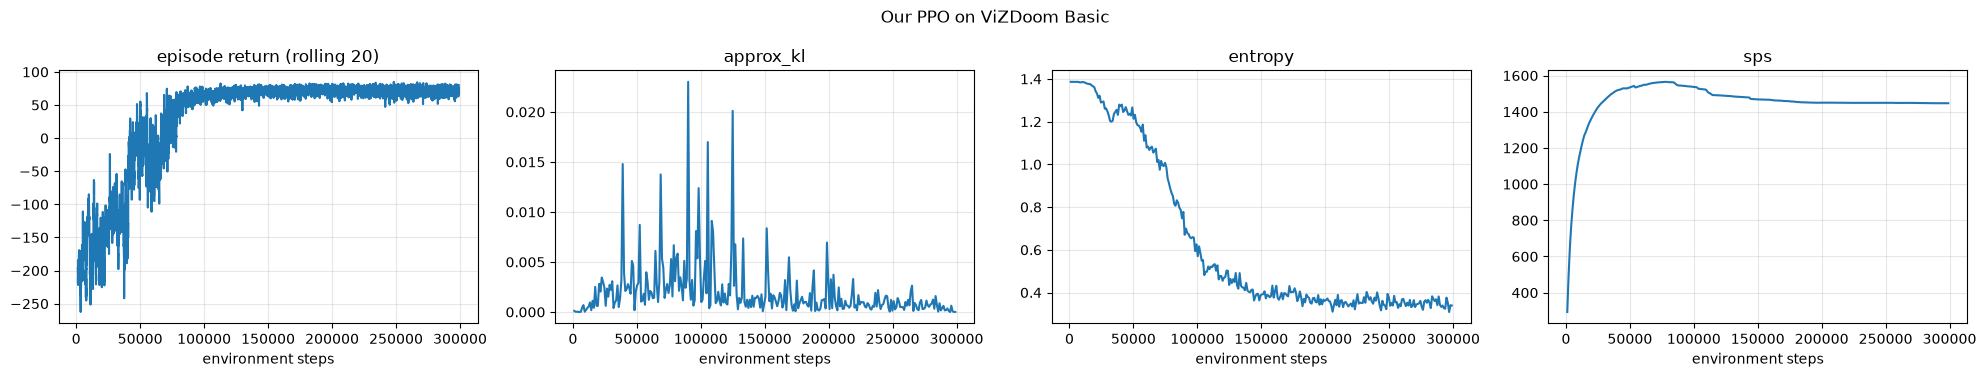

In [7]:
basic_cfg = PixelPPOConfig(scenario="Basic", total_steps=300_000, n_envs=8)
t0 = time.time()
basic_agent, basic_log = train_pixel_ppo(basic_cfg)
print(f"trained in {(time.time() - t0) / 60:.1f} min on {DEVICE}")


def plot_pixel_training(log, title):
    fig, ax = plt.subplots(1, 4, figsize=(20, 3.8))
    s = smooth(log["returns"])
    ax[0].plot(np.asarray(log["steps"])[len(log["steps"]) - len(s):], s); ax[0].set_title("episode return (rolling 20)")
    for a, key in zip(ax[1:], ["approx_kl", "entropy", "sps"]):
        a.plot(log["update"], log[key]); a.set_title(key)
    for a in ax:
        a.set_xlabel("environment steps"); a.grid(alpha=.3)
    fig.suptitle(title); plt.tight_layout(); plt.show()

plot_pixel_training(basic_log, "Our PPO on ViZDoom Basic")

### Watch the agent

Doom agents usually play better when they **sample** actions than when they act greedily, so sampling is the default here.

In [8]:
import imageio


def run_episode(policy_fn, scenario, seed=0, frame_skip=4, max_steps=2_000, record=False):
    env = make_doom_env(scenario, frame_skip=frame_skip)
    obs, _ = env.reset(seed=seed)
    frames, G = [], 0.0
    for _ in range(max_steps):
        if record:
            frames.append(env.env.last_rgb.copy())     # env.env = DoomPixels (inside FrameStackObservation)
        obs, r, term, trunc, _ = env.step(policy_fn(obs))
        G += r
        if term or trunc:
            break
    env.close()
    return G, frames


def torch_policy(agent, greedy=False, device=DEVICE):
    def act(obs):
        with torch.no_grad():
            logits, _ = agent(torch.as_tensor(obs, device=device).unsqueeze(0))
        return int(logits.argmax()) if greedy else int(Categorical(logits=logits).sample())
    return act


def save_video(frames, path, fps=35 // 4):
    try:
        imageio.mimsave(path, frames, fps=fps)                              # .mp4 (needs imageio-ffmpeg)
    except Exception as e:
        path = str(Path(path).with_suffix(".gif"))
        imageio.mimsave(path, frames, duration=int(1000 / fps), loop=0)     # GIF fallback
    print("saved", path)
    return path


scores = [run_episode(torch_policy(basic_agent), "Basic", seed=s)[0] for s in range(10)]
print(f"Basic: mean return over 10 episodes {np.mean(scores):.1f} ± {np.std(scores):.1f}")
_, frames = run_episode(torch_policy(basic_agent), "Basic", seed=123, record=True)
save_video(frames, "doom_basic_ppo.mp4")

Basic: mean return over 10 episodes 67.8 ± 26.7
saved doom_basic_ppo.mp4


'doom_basic_ppo.mp4'

## B2. (Optional) `DefendCenter`

A step up: monsters approach from every side, and ammunition is limited. Expect about 1M steps.

In [9]:
RUN_DEFEND = True
if RUN_DEFEND:
    defend_agent, defend_log = train_pixel_ppo(PixelPPOConfig(scenario="DefendCenter", total_steps=1_000_000,
                                                              n_envs=8), print_every=25)
    plot_pixel_training(defend_log, "Our PPO on ViZDoom DefendCenter")
    _, frames = run_episode(torch_policy(defend_agent), "DefendCenter", seed=7, record=True)
    save_video(frames, "doom_defendcenter_ppo.mp4")

# Part C: Synchronous vs asynchronous PPO

Our PPO is **synchronous**. It alternates between two phases, and each one waits for the other:

```
collect rollout ──► update network ──► collect rollout ──► update network ──► ...
(GPU waits)          (envs wait)        (GPU waits)          (envs wait)
```

Sample Factory and RLlib's **APPO** are **asynchronous**. Actors collect experience *continuously* while the
learner trains *continuously*, and new weights are broadcast to the actors from time to time:

```
actors:   rollout ─ rollout ─ rollout ─ rollout ─ rollout ─ ...      (always busy)
                  ↘         ↘          ↘          ↘
learner:            update ─── update ─── update ─── update ─ ...    (always busy)
                       ↖ new weights broadcast to the actors ↙
```

This keeps both the CPUs and the GPU busy. It's why Sample Factory can reach very high frame rates.

**The cost is policy lag.** By the time the learner uses a batch, its weights $\pi$ have already moved on from the
weights $\mu$ that *collected* the batch. The data is slightly **off-policy**, and plain GAE would be biased.

### The fix: V-trace (Espeholt et al., 2018, IMPALA)
V-trace corrects the value targets with **truncated importance weights**,
$\rho_t = \min\big(\bar\rho, \frac{\pi(a_t \mid s_t)}{\mu(a_t \mid s_t)}\big)$ and
$c_t = \lambda \min\big(\bar c, \frac{\pi(a_t \mid s_t)}{\mu(a_t \mid s_t)}\big)$:

$$v_s = V(s_s) + \sum_{t \ge s} \gamma^{t-s} \Big(\prod_{i=s}^{t-1} c_i\Big)\, \rho_t \big(r_t + \gamma V(s_{t+1}) - V(s_t)\big)$$

- If the actions are *more* likely under the old policy than the new one ($\pi/\mu < 1$), the correction shrinks
  their influence.
- The truncation at $\bar\rho = \bar c = 1$ caps the weights, which keeps the variance under control.
- **Sanity check:** when there is no lag ($\pi = \mu$, so every ratio is 1) and $\lambda = 1$, V-trace reduces to the
  ordinary *n*-step bootstrapped return. We verify that below.

APPO combines these V-trace targets with PPO's clipped surrogate objective, and usually a target network as well.

In [10]:
def vtrace(rewards, values, bootstrap_value, dones, log_rhos, gamma=0.99, lam=1.0, rho_bar=1.0, c_bar=1.0):
    '''V-trace targets for one trajectory (arrays of length T). log_rhos = log pi(a|s) - log mu(a|s).'''
    rhos = np.exp(log_rhos)
    clipped_rho = np.minimum(rho_bar, rhos)
    cs = lam * np.minimum(c_bar, rhos)
    not_done = 1.0 - dones
    next_values = np.append(values[1:], bootstrap_value)
    deltas = clipped_rho * (rewards + gamma * next_values * not_done - values)

    acc, vs_minus_v = 0.0, np.zeros_like(values)
    for t in reversed(range(len(rewards))):
        acc = deltas[t] + gamma * cs[t] * not_done[t] * acc
        vs_minus_v[t] = acc
    return values + vs_minus_v


rng = np.random.default_rng(0)
T = 10
rewards, values = rng.normal(size=T), rng.normal(size=T)
dones, bootstrap = np.zeros(T), 0.5

# 1) no policy lag (pi == mu) and lambda = 1  ->  V-trace == n-step bootstrapped return
nstep = np.zeros(T); G = bootstrap
for t in reversed(range(T)):
    G = rewards[t] + 0.99 * G
    nstep[t] = G
assert np.allclose(vtrace(rewards, values, bootstrap, dones, np.zeros(T)), nstep)
print("check passed: with pi == mu, V-trace equals the n-step return")

# 2) with policy lag: how much the targets move as the policies drift apart
for drift in [0.0, 0.1, 0.5, 1.0]:
    log_rhos = rng.normal(scale=drift, size=T)
    vs = vtrace(rewards, values, bootstrap, dones, log_rhos)
    print(f"log-ratio std {drift:.1f}: mean |V-trace - n-step return| = {np.mean(np.abs(vs - nstep)):.3f}")

check passed: with pi == mu, V-trace equals the n-step return
log-ratio std 0.0: mean |V-trace - n-step return| = 0.000
log-ratio std 0.1: mean |V-trace - n-step return| = 0.095
log-ratio std 0.5: mean |V-trace - n-step return| = 0.239
log-ratio std 1.0: mean |V-trace - n-step return| = 1.199


# Part D: RLlib APPO on Health Gathering Supreme

Now the course's task, with a library built for this kind of scale. RLlib's **APPO** is the same algorithm family as
Sample Factory's:
- asynchronous env runners,
- V-trace corrected targets, and
- a PPO-style clipped objective.

It's configured the same way as the PPO in notebook 6.

**Two adaptations for RLlib:**
- **Channel order:** RLlib's built-in CNN expects channels-last images, `(84, 84, 4)`, while our PyTorch CNN used
  channels-first, `(4, 84, 84)`.
- **Scaling:** we hand RLlib `float32` values in [0, 1], because its default CNN doesn't divide by 255.

As in notebook 6, we pass RLlib the **environment class**, not a registered name, so it works in every worker process.

In [11]:
import ray
from ray.rllib.algorithms.appo import APPOConfig
from ray.rllib.core.rl_module.default_model_config import DefaultModelConfig
from ray.rllib.utils.metrics import ENV_RUNNER_RESULTS, EPISODE_RETURN_MEAN, NUM_ENV_STEPS_SAMPLED_LIFETIME

ray.init(ignore_reinit_error=True, include_dashboard=False)
N_CPUS = int(ray.cluster_resources().get("CPU", 2))
USE_GPU = torch.cuda.is_available()          # RLlib's GPU support targets CUDA; on a Mac the learner uses the CPU
print("ray", ray.__version__, "| CPUs:", N_CPUS, "| CUDA GPU for the learner:", USE_GPU)


class DoomRLlibEnv(gym.Wrapper):
    '''ViZDoom + our preprocessing, as channels-last float images for RLlib's CNN, with reward scaling.'''
    def __init__(self, config=None):
        from vizdoom import gymnasium_wrapper  # noqa: F401  (register the envs inside the worker process)
        c = config or {}
        env = make_doom_env(c.get("scenario", "Basic"), c.get("frame_skip", 4), c.get("size", 84), c.get("frame_stack", 4))
        super().__init__(env)
        self.reward_scale = c.get("reward_scale", 0.01)     # Doom returns are in the hundreds -> keep the value loss small
        k, h, w = env.observation_space.shape
        self.observation_space = gym.spaces.Box(0.0, 1.0, shape=(h, w, k), dtype=np.float32)

    @staticmethod
    def _convert(obs):
        return np.transpose(np.asarray(obs, dtype=np.float32) / 255.0, (1, 2, 0))

    def reset(self, **kwargs):
        obs, info = self.env.reset(**kwargs)
        return self._convert(obs), info

    def step(self, action):
        obs, r, term, trunc, info = self.env.step(action)
        return self._convert(obs), r * self.reward_scale, term, trunc, info


def appo_config(scenario, num_env_runners=None, num_envs_per_env_runner=2, lr=None, reward_scale=0.01):
    # With a CUDA GPU the learner is fast: use many env runners. On a CPU-only machine the learner is the
    # bottleneck: with too many runners, most samples are never trained on (see the note in D1).
    if num_env_runners is None:
        num_env_runners = max(1, min(8, N_CPUS - 2)) if USE_GPU else 2
    lr = lr or (3e-4 if USE_GPU else 5e-4)
    config = (
        APPOConfig()
        .environment(DoomRLlibEnv, env_config={"scenario": scenario, "frame_skip": 4, "reward_scale": reward_scale})
        .env_runners(num_env_runners=num_env_runners, num_envs_per_env_runner=num_envs_per_env_runner)
        .training(
            lr=lr, gamma=0.99,
            train_batch_size_per_learner=1024,
            clip_param=0.2, entropy_coeff=0.01, vf_loss_coeff=0.5, grad_clip=0.5,
        )
        .rl_module(model_config=DefaultModelConfig(
            conv_filters=[[32, 8, 4], [64, 4, 2], [64, 3, 1]],      # the Nature CNN: [channels, kernel, stride]
            conv_activation="relu",
            head_fcnet_hiddens=[512],
            vf_share_layers=True,                                  # one encoder for policy and value, as in Part B
        ))
    )
    if USE_GPU:
        config = config.learners(num_learners=0, num_gpus_per_learner=1)
    return config


def rllib_ppo_config(scenario, num_env_runners=2, num_envs_per_env_runner=4, reward_scale=0.01):
    '''RLlib's SYNCHRONOUS PPO with the same env, CNN and reward scale as APPO (the CPU-friendly choice).'''
    from ray.rllib.algorithms.ppo import PPOConfig as RLlibPPOConfig
    config = (
        RLlibPPOConfig()
        .environment(DoomRLlibEnv, env_config={"scenario": scenario, "frame_skip": 4, "reward_scale": reward_scale})
        .env_runners(num_env_runners=num_env_runners, num_envs_per_env_runner=num_envs_per_env_runner)
        .training(lr=2.5e-4, gamma=0.99, train_batch_size_per_learner=1024, minibatch_size=256, num_epochs=4,
                  clip_param=0.1, entropy_coeff=0.01, vf_loss_coeff=0.5, grad_clip=0.5)
        .rl_module(model_config=appo_config(scenario).model_config)       # identical CNN
    )
    if USE_GPU:
        config = config.learners(num_learners=0, num_gpus_per_learner=1)
    return config


def get_metric(result, key, default=np.nan):
    if key in result:
        return result[key]
    return result.get(ENV_RUNNER_RESULTS, {}).get(key, default)


def train_rllib(config, total_steps, print_every=10):
    algo = config.build_algo()
    scale = (config.env_config or {}).get("reward_scale", 1.0)    # report returns in real (unscaled) Doom units
    log = {"steps": [], "returns": [], "time": [], "trained_ratio": [], "vf_loss": [], "grad_norm": []}
    t0 = time.time()
    while True:
        result = algo.train()
        steps = int(get_metric(result, NUM_ENV_STEPS_SAMPLED_LIFETIME, 0))
        learner = result.get("learners", {})
        trained = learner.get("__all_modules__", {}).get("num_env_steps_trained_lifetime", np.nan)
        policy_stats = learner.get("default_policy", {})
        ratio = trained / steps if steps else np.nan
        log["steps"].append(steps); log["returns"].append(get_metric(result, EPISODE_RETURN_MEAN) / scale)
        log["time"].append(time.time() - t0); log["trained_ratio"].append(ratio)
        log["vf_loss"].append(policy_stats.get("vf_loss", np.nan))
        log["grad_norm"].append(policy_stats.get("gradients_default_optimizer_global_norm", np.nan))
        if result["training_iteration"] % print_every == 0:
            print(f"iter {result['training_iteration']:>5} | steps {steps:>9,} | return mean {log['returns'][-1]:8.2f} "
                  f"| trained/sampled {ratio:.2f} | vf_loss {log['vf_loss'][-1]:.3f} "
                  f"| grad norm {log['grad_norm'][-1]:.2f} | {steps / log['time'][-1]:.0f} SPS")
        if steps >= total_steps:
            return algo, log

/Users/harvindersingh/miniforge3/envs/rl/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026-10-16 12:03:45,800	INFO util.py:155 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.
2026-10-16 12:03:46,630	INFO util.py:155 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.
2026-10-16 12:03:46,988	WARNING authentication_token_setup.py:85 -- Token authentication is enabled for this Ray cluster. Set RAY_AUTH_MODE=disabled to opt out. For more information, see https://docs.ray.io/en/latest/ray-security/token-auth.html
2026-10-16 12:03:49,956	INFO worker.py:2033 -- Started a local Ray instance.


ray 2.59.0 | CPUs: 15 | CUDA GPU for the learner: False


## D1. Quick check on `Basic`

Train RLlib APPO on the same scenario as Part B and compare it with our synchronous PPO.

> **The learner must keep up with the env runners.** In APPO, sampling and learning run in parallel. If the env
> runners produce data faster than the learner can train on it (typical with a CPU learner and a CNN), most samples
> are **never trained on**. Watch `trained/sampled` in the progress output. On a laptop CPU, 8 env runners gave
> about **0.16**: 84% of the experience was thrown away and the agent did not learn. Our synchronous PPO's ratio is
> **4.0**, since every sample is used for 4 epochs. Without a CUDA GPU, `appo_config` therefore defaults to just
> 2 env runners. With a GPU, use many more. That's the setting asynchronous PPO is built for.

> **Scale the rewards.** Basic's returns span about −400 to +100. Without scaling, a test run showed `vf_loss` ≈ 1500,
> `policy_loss` ≈ 0.2 and a gradient norm ≈ 580. The policy and value function share one CNN, so clipping the global
> gradient norm to 0.5 shrank the policy's share of the gradient about 1000×. The policy stayed uniformly random
> through 1M steps. Our own PPO avoids this partly through value-loss clipping. Here we fix the root cause with
> `reward_scale=0.01`. `train_rllib` divides the reported returns back by the scale, so the plots stay in real units.
 Compare both **per
environment step**, where you'd expect similar sample efficiency, and **per second of wall-clock time**, where
asynchronous sampling across many processes should win as you add cores.

(SingleAgentEnvRunner pid=23085) objc[23085]: Class SDL_RumbleMotor is implemented in both /Users/harvindersingh/miniforge3/envs/rl/lib/python3.11/site-packages/cv2/.dylibs/libSDL2-2.0.0.dylib (0x16ac60d40) and /Users/harvindersingh/miniforge3/envs/rl/lib/python3.11/site-packages/pygame/.dylibs/libSDL2-2.0.0.dylib (0x16d2e09c8). This may cause spurious casting failures and mysterious crashes. One of the duplicates must be removed or renamed.
(SingleAgentEnvRunner pid=23085) objc[23085]: Class SDL_RumbleContext is implemented in both /Users/harvindersingh/miniforge3/envs/rl/lib/python3.11/site-packages/cv2/.dylibs/libSDL2-2.0.0.dylib (0x16ac60d90) and /Users/harvindersingh/miniforge3/envs/rl/lib/python3.11/site-packages/pygame/.dylibs/libSDL2-2.0.0.dylib (0x16d2e0a18). This may cause spurious casting failures and mysterious crashes. One of the duplicates must be removed or renamed.
(SingleAgentEnvRunner pid=23085) objc[23085]: Class SDLApplication is implemented in both /Users/harvinder

iter    10 | steps   115,665 | return mean  -194.68 | trained/sampled 0.52 | vf_loss 0.180 | grad norm 0.22 | 1154 SPS
iter    20 | steps   232,744 | return mean  -206.79 | trained/sampled 0.53 | vf_loss 0.226 | grad norm 0.15 | 1161 SPS


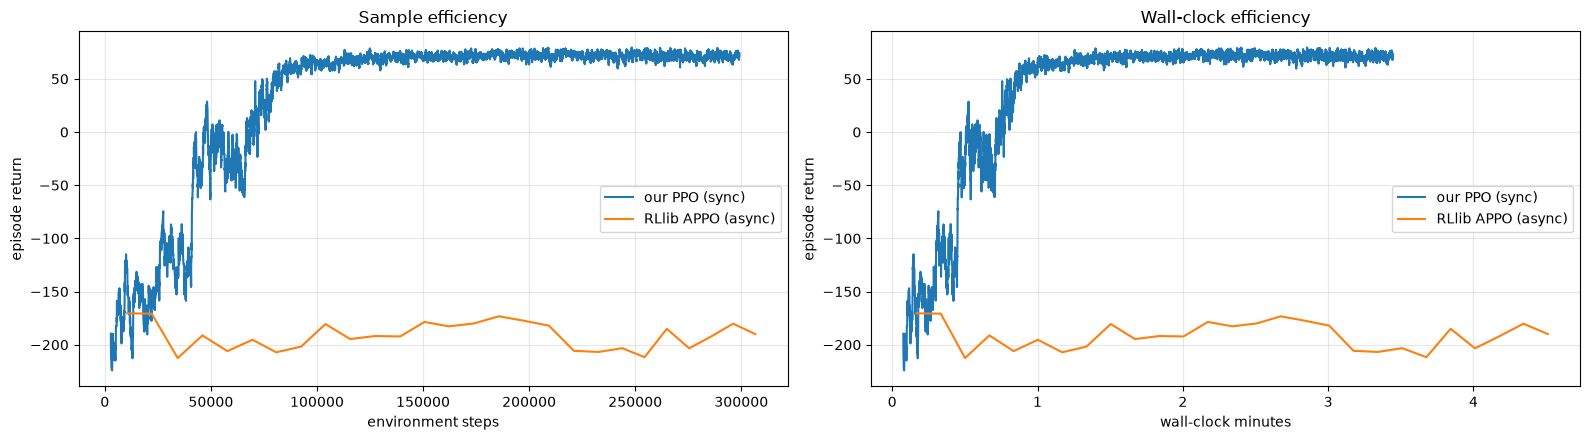

In [14]:
ppo_basic, appo_basic_log = train_rllib(appo_config("Basic"), total_steps=300_000)

fig, ax = plt.subplots(1, 2, figsize=(16, 4.5))
s = smooth(basic_log["returns"], 50)
ours_steps = np.asarray(basic_log["steps"])[len(basic_log["steps"]) - len(s):]
ax[0].plot(ours_steps, s, label="our PPO (sync)")
ax[0].plot(appo_basic_log["steps"], appo_basic_log["returns"], label="RLlib APPO (async)")
ax[0].set(xlabel="environment steps", ylabel="episode return", title="Sample efficiency")

ours_time = np.interp(ours_steps, basic_log["update"], np.asarray(basic_log["update"]) / np.asarray(basic_log["sps"]))
ax[1].plot(ours_time / 60, s, label="our PPO (sync)")
ax[1].plot(np.asarray(appo_basic_log["time"]) / 60, appo_basic_log["returns"], label="RLlib APPO (async)")
ax[1].set(xlabel="wall-clock minutes", ylabel="episode return", title="Wall-clock efficiency")
for a in ax:
    a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.show()



## D1b. Synchronous PPO in RLlib: the control experiment

If APPO doesn't learn, is the problem APPO or our RLlib setup? RLlib's **synchronous PPO** uses the *same* environment
wrapper, CNN and reward scale, but re-uses each batch for several epochs, like our PPO.

On a laptop CPU (M-series Mac, 2 env runners), a test run gave:

| | Throughput | Basic solved? |
|---|---|---|
| our PPO | ~1,550 steps/s | yes, ~70–75 after ~100k steps (about 1 min) |
| RLlib PPO | ~230 steps/s | yes, **~80 after ~60k steps** (about 4 min), entropy 0.015 at the end |
| RLlib APPO | ~1,150 steps/s | **no**: still random after 300k steps |

So the RLlib pipeline is correct, and APPO's problem is the asynchronous design itself on this hardware: little data
reuse, policy lag damped by V-trace, and no fast GPU learner to keep busy.

*About `trained/sampled`:* RLlib's PPO adds the whole train batch to its counter on every mini-batch update. With
4 epochs × 4 mini-batches it reports about 17–21, though each sample is really used 4 times. Don't compare this
counter directly across algorithms.

In [ ]:
rllib_ppo_basic, rllib_ppo_log = train_rllib(rllib_ppo_config("Basic"), total_steps=300_000)

fig, ax = plt.subplots(1, 2, figsize=(16, 4.5))
s = smooth(basic_log["returns"], 50)
ours_steps = np.asarray(basic_log["steps"])[len(basic_log["steps"]) - len(s):]
ours_time = np.interp(ours_steps, basic_log["update"], np.asarray(basic_log["update"]) / np.asarray(basic_log["sps"]))
curves = {
    "our PPO (sync)": (ours_steps, ours_time, s),
    "RLlib PPO (sync)": (rllib_ppo_log["steps"], rllib_ppo_log["time"], rllib_ppo_log["returns"]),
    "RLlib APPO (async)": (appo_basic_log["steps"], appo_basic_log["time"], appo_basic_log["returns"]),
}
for name, (steps, secs, rets) in curves.items():
    ax[0].plot(steps, rets, label=name)
    ax[1].plot(np.asarray(secs) / 60, rets, label=name)
ax[0].set(xlabel="environment steps", ylabel="episode return", title="Sample efficiency")
ax[1].set(xlabel="wall-clock minutes", ylabel="episode return", title="Wall-clock efficiency")
for a in ax:
    a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

r = rllib_ppo_basic.train()
print("RLlib PPO entropy:", r["learners"]["default_policy"].get("entropy"), "(random = log 4 = 1.39)")

2026-10-16 12:21:06,619	WARNING algorithm_config.py:5160 -- You are running PPO on the new API stack! This is the new default behavior for this algorithm. If you don't want to use the new API stack, set `config.api_stack(enable_rl_module_and_learner=False,enable_env_runner_and_connector_v2=False)`. For a detailed migration guide, see here: https://docs.ray.io/en/master/rllib/new-api-stack-migration-guide.html
(SingleAgentEnvRunner pid=23093) objc[23093]: Class SDL_RumbleMotor is implemented in both /Users/harvindersingh/miniforge3/envs/rl/lib/python3.11/site-packages/cv2/.dylibs/libSDL2-2.0.0.dylib (0x153950d40) and /Users/harvindersingh/miniforge3/envs/rl/lib/python3.11/site-packages/pygame/.dylibs/libSDL2-2.0.0.dylib (0x1563dc9c8). This may cause spurious casting failures and mysterious crashes. One of the duplicates must be removed or renamed.
(SingleAgentEnvRunner pid=23093) objc[23093]: Class SDL_RumbleContext is implemented in both /Users/harvindersingh/miniforge3/envs/rl/lib/pyt

iter    10 | steps    10,266 | return mean  -186.93 | trained/sampled 17.48 | vf_loss 0.986 | grad norm 0.22 | 246 SPS
iter    20 | steps    20,537 | return mean  -185.61 | trained/sampled 17.49 | vf_loss 0.584 | grad norm 1.15 | 244 SPS
iter    30 | steps    30,803 | return mean   -49.59 | trained/sampled 17.50 | vf_loss 0.763 | grad norm 4.80 | 245 SPS
iter    40 | steps    41,067 | return mean    11.61 | trained/sampled 17.63 | vf_loss 0.292 | grad norm 0.58 | 246 SPS
iter    50 | steps    51,335 | return mean    52.26 | trained/sampled 17.99 | vf_loss 0.080 | grad norm 0.52 | 243 SPS
iter    60 | steps    61,603 | return mean    67.35 | trained/sampled 18.45 | vf_loss 0.025 | grad norm 0.82 | 242 SPS
iter    70 | steps    71,869 | return mean    72.28 | trained/sampled 18.89 | vf_loss 0.025 | grad norm 0.84 | 241 SPS
iter    80 | steps    82,142 | return mean    77.58 | trained/sampled 19.26 | vf_loss 0.012 | grad norm 1.66 | 239 SPS
iter    90 | steps    92,411 | return mean    75

## D2. Health Gathering Supreme, the course's task

The agent stands on an acid floor that slowly drains its health. It must find and pick up medkits, avoid poison
vials, and survive as long as possible. Everything has to be learned from pixels.

- **Budget:** about 4M environment steps, as in the course. With a CUDA GPU and 8 or more CPU cores that's an hour or
  two. On a laptop CPU it's many hours, so consider Colab with a GPU.
- **What good looks like:** episodes get **longer**, because the agent survives, and the return rises. A random
  agent dies quickly.

In [ ]:
RUN_HGS = False
HGS_STEPS = 4_000_000

# APPO pays off with a fast GPU learner and many env runners; on a CPU-only machine, synchronous PPO learns (D1b)
HGS_ALGO = "APPO" if USE_GPU else "PPO"

if RUN_HGS:
    hgs_config = appo_config("HealthGatheringSupreme") if HGS_ALGO == "APPO" else rllib_ppo_config("HealthGatheringSupreme")
    print("training with RLlib", HGS_ALGO)
    appo_hgs, appo_hgs_log = train_rllib(hgs_config, total_steps=HGS_STEPS, print_every=25)

    plt.figure(figsize=(9, 4.5))
    plt.plot(appo_hgs_log["steps"], appo_hgs_log["returns"])
    plt.xlabel("environment steps"); plt.ylabel("episode return (RLlib running mean)")
    plt.title(f"RLlib {HGS_ALGO} on Health Gathering Supreme"); plt.grid(alpha=.3); plt.show()

    ckpt = Path("rllib_checkpoints/doom_hgs").absolute()
    appo_hgs.save_to_path(str(ckpt))
    print("checkpoint saved to", ckpt)

### Watch the RLlib agent

The new API stack represents the policy as an `RLModule`, and `forward_inference` returns the action logits.

In [ ]:
def rllib_policy(algo, greedy=False):
    module = algo.get_module()
    def act(obs):
        x = torch.as_tensor(DoomRLlibEnv._convert(obs)).unsqueeze(0)
        with torch.no_grad():
            logits = module.forward_inference({"obs": x})["action_dist_inputs"]
        return int(logits.argmax(dim=-1)[0]) if greedy else int(Categorical(logits=logits).sample()[0])
    return act


if RUN_HGS:
    algo_to_watch, scenario_to_watch = appo_hgs, "HealthGatheringSupreme"
else:   # prefer the RLlib agent that actually learned Basic
    algo_to_watch, scenario_to_watch = globals().get("rllib_ppo_basic") or appo_basic, "Basic"
scores = [run_episode(rllib_policy(algo_to_watch), scenario_to_watch, seed=s)[0] for s in range(5)]
print(f"{scenario_to_watch}: mean return over 5 episodes {np.mean(scores):.1f} ± {np.std(scores):.1f}")
_, frames = run_episode(rllib_policy(algo_to_watch), scenario_to_watch, seed=42, record=True)
VIDEO = save_video(frames, f"doom_{scenario_to_watch.lower()}_appo.mp4")

### Share it on the Hugging Face Hub

The course uses Sample Factory's own upload script. With the plain `huggingface_hub` library you can upload any
model: the weights or checkpoint, the video, and a short model card. Log in once with `hf auth login`
(or `huggingface-cli login` on older versions), using a token with write access.

In [ ]:
PUSH_TO_HUB = False
HF_REPO = "your-hf-username/appo-vizdoom-health-gathering-supreme"     # <- change

if PUSH_TO_HUB:
    from huggingface_hub import HfApi
    upload_dir = Path("hub_upload"); upload_dir.mkdir(exist_ok=True)
    if RUN_HGS:
        algo_to_watch.save_to_path(str((upload_dir / "rllib_checkpoint").absolute()))
    Path(VIDEO).replace(upload_dir / Path(VIDEO).name)
    (upload_dir / "README.md").write_text(f'''---
library_name: ray-rllib
tags: [reinforcement-learning, deep-reinforcement-learning, vizdoom, appo]
---
# APPO on ViZDoom {scenario_to_watch}

Trained with RLlib (new API stack, APPO or PPO) from 84x84x4 grayscale frames, frame skip 4, reward scale 0.01.
Mean return over 5 evaluation episodes: {np.mean(scores):.2f} ± {np.std(scores):.2f}
''')
    api = HfApi()
    api.create_repo(HF_REPO, exist_ok=True)
    api.upload_folder(folder_path=str(upload_dir), repo_id=HF_REPO, commit_message="APPO ViZDoom agent")
    print(f"uploaded to https://huggingface.co/{HF_REPO}")

In [ ]:
for algo in [a for a in (globals().get("appo_basic"), globals().get("rllib_ppo_basic"), globals().get("appo_hgs"))
             if a is not None]:
    algo.stop()
ray.shutdown()

# Part E (appendix): the original Sample Factory route

Sample Factory is still one of the fastest single-machine PPO implementations for pixel environments, and it runs
on Linux and macOS. The course trains with roughly:

```bash
pip install sample-factory vizdoom
python -m sf_examples.vizdoom.train_vizdoom --env=doom_health_gathering_supreme \
    --num_workers=8 --num_envs_per_worker=4 --train_for_env_steps=4000000
```

Check the course page or the Sample Factory docs for the exact current flags, including the evaluation and
`--push_to_hub` options. Here is how its main settings map to RLlib and to our PPO:

| Sample Factory | RLlib APPO | Our `PixelPPOConfig` |
|---|---|---|
| `--num_workers` | `num_env_runners` | (one process per env) |
| `--num_envs_per_worker` | `num_envs_per_env_runner` | `n_envs` |
| `--rollout` | `rollout_fragment_length` | `n_steps` |
| `--batch_size` | `train_batch_size_per_learner` (and `minibatch_size`) | `minibatch_size` |
| `--num_epochs` | (APPO reuses batches via its circular buffer) | `update_epochs` |
| `--learning_rate` | `lr` | `lr` |
| `--gamma` | `gamma` | `gamma` |
| `--exploration_loss_coeff` | `entropy_coeff` | `ent_coef` |
| `--value_loss_coeff` | `vf_loss_coeff` | `vf_coef` |
| `--ppo_clip_ratio` | `clip_param` | `clip_coef` |
| `--with_vtrace` | `vtrace` (on by default) | (synchronous, no lag) |
| `--env_frameskip` | `frame_skip` in our env | `frame_skip` |
| `--train_for_env_steps` | stop criterion | `total_steps` |

## Summary

| Concept | Where |
|---|---|
| Pixel preprocessing, frame stacking, frame skip | Part A |
| Parallel environments with correct autoreset handling | `make_vector_env` (`SAME_STEP`) |
| PPO with a CNN, on a GPU (CUDA or MPS) | `train_pixel_ppo` (Part B) |
| Synchronous vs asynchronous training, policy lag | Part C |
| V-trace correction (implemented and checked) | `vtrace` (Part C) |
| Scalable asynchronous PPO | RLlib APPO (Part D) |

**Next steps**
- **Recurrent policies:** Doom is partially observable. Try RLlib's `DefaultModelConfig(use_lstm=True)` and
  compare it with frame stacking.
- **Harder scenarios:** `DeadlyCorridor`, `MyWayHome` (sparse reward, a good fit for the RND from notebook 6),
  and `Deathmatch`.
- **Tune APPO with Ray Tune,** as in notebooks 4 and 6, but pick the best trial *after* training. Early iterations
  may have no finished episodes yet.

## References
- Hugging Face Deep RL Course, [Unit 8 Part 2](https://huggingface.co/learn/deep-rl-course/unit8/introduction-sf)
- Kempka et al., 2016, *ViZDoom: A Doom-based AI Research Platform for Visual Reinforcement Learning*, and the [ViZDoom docs](https://vizdoom.farama.org/)
- Espeholt et al., 2018, *IMPALA: Scalable Distributed Deep-RL with Importance Weighted Actor-Learner Architectures* (V-trace)
- Petrenko et al., 2020, *Sample Factory: Egocentric 3D Control from Pixels at 100000 FPS with Asynchronous Reinforcement Learning*
- Schulman et al., 2017, *Proximal Policy Optimization Algorithms*
- [CleanRL](https://github.com/vwxyzjn/cleanrl) `ppo_atari.py`, and the [RLlib docs](https://docs.ray.io/en/latest/rllib/index.html)